# Task 1: Ensemble Learning on HW4 Data
**Approach:** 
1. Check the class balance and preprocess the data (one-hot encode categorical data, scale numerical data for the linear model)
2. Tune four different base models (random forest, extra trees, gradient boosting, and logistic regression) with randomized search and 5-fold CV on a split of the training data.
3. Combine the models into ensembles (soft voting, stacking) and then compare against the single models using CV AUC.
4. Check the winner on a held-out validation split, then refit on all labeled data and write the predictions to `test_result_HW6Ensemble.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier, StackingClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 72

### Load the data and inspect class balance
`train_dataHW4.csv` (7,595 labeled rows, 24 features) is used for fitting and evaluation, and `test_dataHW4.csv` (2,532 rows) is only predicted at the end. The target is `Class`, and we predict the probability of class 2.

In [2]:
# Read and save the data sets from HW4
train = pd.read_csv("train_dataHW4.csv")
test = pd.read_csv("test_dataHW4.csv")

X = train.drop(columns="Class") # Features
y = train["Class"] # Labels (predicting the probability of class 2)

print("Train shape:", X.shape, "| Test shape:", test.shape)
# Class balance matters: ~84% class 1 vs ~16% class 2, so accuracy would be misleading (hence AUC)
print("Class balance:\n", y.value_counts(normalize=True).round(4))
print("Missing values in train", int(train.isna().sum().sum())) # 0 means no imputation is needed

Train shape: (7595, 24) | Test shape: (2532, 24)
Class balance:
 Class
1    0.8394
2    0.1606
Name: proportion, dtype: float64
Missing values in train 0


### Preprocessing
Categorical columns are one-hot encoded. Tree models do not need scaling, but logistic regression does so there are two preprocessors.

The preprocessing sits inside a scikit-learn `Pipeline`, so during cross-validation it is re-fit on each training fold and nothing leaks from the held-out fold. 20% of the labeled data is set aside as a validation split (stratified), and all tuning uses only the other 80%.

In [3]:
# Save categorical columns and numerical columns for different preprocessing
cat_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numeric_cols = X.columns.difference(cat_cols).tolist()

# Build a preprocessor: one-hot encode categoricals; optionally standardize numerics.
# handle_unknown="ignore" avoids errors if a category only appears in a validation/test fold.
def make_preprocess(scale_numeric):
    num = StandardScaler() if scale_numeric else "passthrough" # Trees don't need scaling, only logistic regression does
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", num, numeric_cols)
    ])
# Hold out 20% of the labeled data as a validation set (stratified keeps the class ratio the same).
# All tuning and model comparison below use only X_train; X_val is only used for a final check.
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
# 5-fold stratified cross-validation, shared by every search/comparison so scores are comparable
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

### Tune base models
Each model gets its own randomized search (AUC, 5-fold CV, training split only). Randomized search tries a fixed number of random combinations of hyperparameters (20 draws for the tree models, 5 for logistic regression whose grid has only 5 values), which is much cheaper than a full grid search and usually finds a similar result.

| Model | Why it is included | Hyperparameters tuned |
|---|---|---|
| Random forest | Averages many deep trees trained on bootstrap samples (bagging) | depth, minimum leaf size, features per split |
| Extra trees | Like a random forest with random split thresholds, so its errors are less correlated | depth, minimum leaf size, features per split |
| Gradient boosting | Builds trees one after another, each fixing the previous errors (boosting) | learning rate, leaves per tree, minimum leaf size, number of iterations |
| Logistic regression | Simple linear baseline, to see how much the non-linear models add | regularization strength `C` |

**Result:** best CV AUC was 0.951 for gradient boosting, 0.940 for random forest, 0.934 for extra trees and 0.886 for logistic regression. The gap between the linear model and the tree models suggests the relationship between the features and the class is non-linear and/or involves interactions.

In [4]:
# Tune one model: randomized search over its hyperparameters, scored by AUC with 5-fold CV 
def tune(name, estimator, space, scale, n_iter):
    # Pipeline does preprocessing and tunes model so encoding is re-fit in each CV fold
    pipe = Pipeline([("prep", make_preprocess(scale)), ("model", estimator)])
    # Never ask for more random draws than there are combinations in the grid
    n_iter = min(n_iter, len(ParameterGrid(space)))
    search = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring="roc_auc", cv=cv, random_state=SEED, n_jobs=-1, return_train_score=True)
    search.fit(X_train, y_train)
    print(f"{name:<8}: best CV AUC = {search.best_score_:.4f}  {search.best_params_}")
    return search

spaces = {
    # Random forest: bagged deep trees; tune depth, leaf size and features per split
    "Random forest": (RandomForestClassifier(n_estimators=300, criterion="entropy", random_state=SEED), False, 20, {
        "model__max_depth": [None, 6, 14, 20, 25, 40], "model__min_samples_leaf": [1, 2, 4, 8], "model__max_features": [0.3, 0.5, 0.7]}),
    # Extra trees: like a random forest but with random split thresholds (more variance reduction)   
    "Extra trees": (ExtraTreesClassifier(n_estimators=300, criterion="entropy", random_state=SEED), False, 20, {
        "model__max_depth": [None, 6, 14, 20, 25, 40], "model__min_samples_leaf": [1, 2, 4, 8, 16], "model__max_features": [0.1, 0.3, 0.5]}),
    # Gradient boosting (histogram-based): trees built sequentially, each correcting the previous errors
    "Gradient boosting": (HistGradientBoostingClassifier(l2_regularization=0, random_state=SEED), False, 20, {
        "model__learning_rate": [0.03, 0.05, 0.1], "model__max_leaf_nodes": [5, 10, 15, 20], "model__min_samples_leaf": [2, 3, 5, 10], "model__max_iter": [200, 400]}),
    # Logistic regression: linear baseline; C = inverse regularization strength (needs scaled inputs)   
    "Logistic regression": (LogisticRegression(max_iter=2000), True, 5, {"model__C": [0.01, 0.05, 0.03, 0.1, 1]}),
}
# Run the search for every base model and keep the best fitted pipeline of each 
searches = {n: tune(n, est, sp, scale, it) for n, (est, scale, it, sp) in spaces.items()}
tuned = {n: s.best_estimator_ for n, s in searches.items()}

Random forest: best CV AUC = 0.9403  {'model__min_samples_leaf': 4, 'model__max_features': 0.5, 'model__max_depth': 25}
Extra trees: best CV AUC = 0.9338  {'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 25}
Gradient boosting: best CV AUC = 0.9510  {'model__min_samples_leaf': 3, 'model__max_leaf_nodes': 15, 'model__max_iter': 400, 'model__learning_rate': 0.05}
Logistic regression: best CV AUC = 0.8864  {'model__C': 0.03}


### Build the ensembles and compare
Ensemble methods combine several models so that their individual errors partly cancel out. I compare each single tuned model with four ensembles, all scored with the same 5-fold CV on the training split:

- **Soft vote (RF+ET):** average the predicted probabilities of random forest and extra trees. These are both bagging-style models, so they make similar mistakes and the gain is small.
- **Soft vote (all four):** average all four models. Including the weak logistic regression with equal weight dilutes the stronger models.
- **Stacking (all four):** a logistic regression learns how to combine the four models' out-of-fold probabilities.
- **Soft vote (weighted):** random forest and gradient boosting with weights 1 and 10, so it is mostly gradient boosting with a small correction from the forest.

In [5]:
def fresh(name): # Return an unfit copy of the `name` tuned pipeline
    return clone(tuned[name])

# Candidate models: the four tuned single models plus several ensembles
base_models = list(tuned)
models = {n: fresh(n) for n in base_models}
# Soft voting = average the predicted probabilities of the member models
models["Soft vote (RF+ET)"] = VotingClassifier([
    ("rf", fresh("Random forest")), ("et", fresh("Extra trees"))], voting="soft")
models["Soft vote (all four)"] = VotingClassifier([(n[:3], fresh(n)) for n in base_models], voting="soft")
# Stacking = train a logistic regression on the base models' out-of-fold predicted probabilities
models["Stacking (all four)"] = StackingClassifier(
    [(n[:3], fresh(n)) for n in base_models], final_estimator=LogisticRegression(max_iter=2000), cv=cv, stack_method="predict_proba")
# Weighted soft vote of random forest and gradient boosting. The weights [1, 10] mean the
# gradient boosting probabilities count 10x as much as the random forest's.
# The other members were tried and commented out because they did not improve CV AUC.
models["Soft vote (weighted)"] = VotingClassifier(
    [
        ("rf", fresh("Random forest")),
        # ("et", fresh("Extra trees")),
        ("gb", fresh("Gradient boosting")),
        # ("lr", fresh("Logistic regression")),
    ],
    voting="soft",
    weights=[1, 10], # best so far [1, 10] mean auc=0.9512 std=0.0088
)
# 5-fold CV AUC on the training split for every candidate (same folds for all, so comparable)
cv_scores = {n: cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1) for n, m in models.items()}
comparison = (pd.DataFrame({"mean_cv_auc": {n: s.mean() for n, s in cv_scores.items()},
                            "std": {n: s.std() for n, s in cv_scores.items()}}).sort_values("mean_cv_auc"))
display(comparison.round(4))

,mean_cv_auc,std
Logistic regression,0.8864,0.0120
Extra trees,0.9338,0.0128
Random forest,0.9403,0.0084
Soft vote (RF+ET),0.9406,0.0096
Soft vote (all four),0.9417,0.0101
Stacking (all four),0.9463,0.0103
Gradient boosting,0.9510,0.0091
Soft vote (weighted),0.9513,0.0088


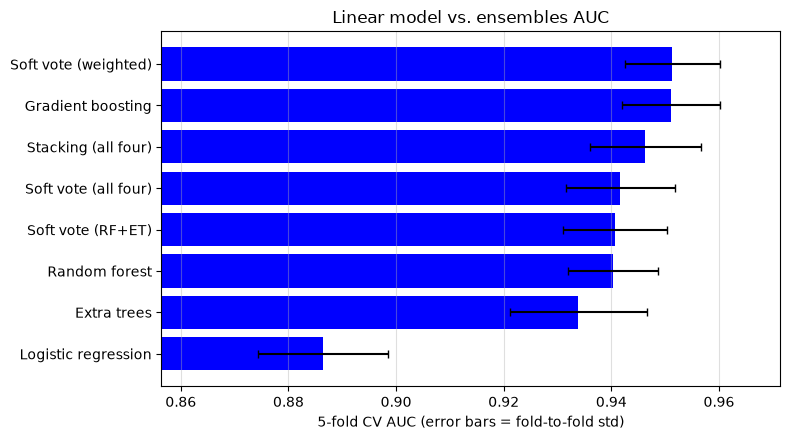

In [6]:
# Bar chart of mean CV AUC per model; error bars show the fold-to-fold standard deviation
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(comparison.index, comparison["mean_cv_auc"], xerr=comparison["std"], capsize=3, color="blue")
# Zoom the x-axis so the differences between models are visible
ax.set_xlim(comparison["mean_cv_auc"].min() - 0.03, min(1, comparison["mean_cv_auc"].max() + 0.02))
ax.set_xlabel("5-fold CV AUC (error bars = fold-to-fold std)")
ax.set_title("Linear model vs. ensembles AUC")
ax.grid(axis="x", alpha=0.4)
plt.tight_layout(); plt.show()

In [7]:
# Selected model: the weighted soft vote (highest mean CV AUC in the table above).
best_name = "Soft vote (weighted)" # comparison["mean_cv_auc"].idxmax()
print("Selected ensemble:", best_name)

Selected ensemble: Soft vote (weighted)


**Results of the comparison:** the weighted soft vote has the highest mean CV AUC (0.9513), followed closely by gradient boosting alone (0.9510) and then stacking (0.9463). The two simple soft votes of weaker models (0.9406 and 0.9417) are no better than their best member. The linear model is clearly worst (0.886).

**Caveat:** the weighted vote beats gradient boosting by only 0.0003 AUC, while the fold-to-fold standard deviation is about 0.009, so this difference is well within noise. I also picked the weights `[1, 10]` by trying a few values and looking at the same CV scores, which makes its CV score slightly optimistic. The practical conclusion is that boosting carries most of the performance, and the ensemble adds a small, not clearly significant, improvement.

### Check on held-out validation split
To get an estimate that was not used for tuning or choosing weights, each model is refit on the training split and scored on the 20% validation split.

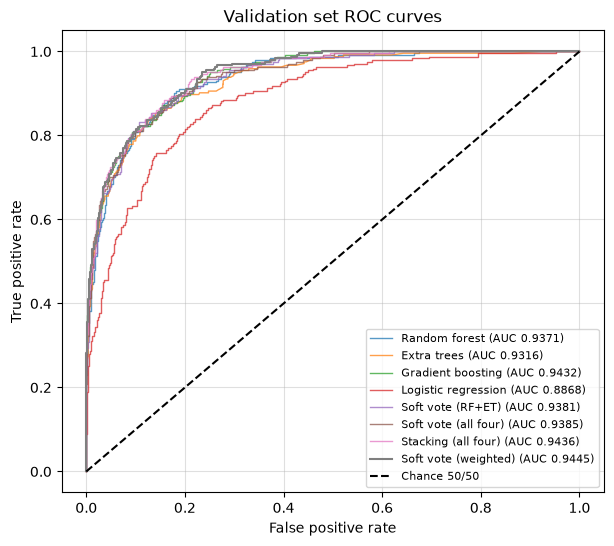

               model  validation_auc
 Logistic regression        0.886770
         Extra trees        0.931631
       Random forest        0.937136
   Soft vote (RF+ET)        0.938087
Soft vote (all four)        0.938489
   Gradient boosting        0.943157
 Stacking (all four)        0.943562
Soft vote (weighted)        0.944529


In [8]:
# Validation check: refit every model on the training split and score it on the untouched
# validation split (labels are 1/2, so convert to 0/1 where 1 = class 2 for the AUC)
y_val_bin = (y_val == 2).astype(int)
fitted, rows = {}, []
plt.figure(figsize=(7, 6))
for n, m in models.items():
    m = clone(m).fit(X_train, y_train)
    fitted[n] = m
    # Predicted probability of class 2 (look up its column rather than assuming it is column 1)
    p = m.predict_proba(X_val)[:, list(m.classes_).index(2)]
    auc = roc_auc_score(y_val_bin, p)
    rows.append((n, auc))
    # ROC curve; the selected model is drawn with a thicker, more opaque line
    fpr, tpr, _ = roc_curve(y_val_bin, p)
    plt.plot(fpr, tpr, lw=1.5 if n == best_name else 1, alpha=0.75 if n != best_name else 1, label=f"{n} (AUC {auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance 50/50") # Random guess
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Validation set ROC curves"); plt.legend(fontsize=8, loc="lower right")
plt.grid(alpha=0.4); plt.show()
print(pd.DataFrame(rows, columns=["model", "validation_auc"]).sort_values("validation_auc").to_string(index=False))

**Validation results:** the ranking agrees with CV. The weighted soft vote has the best validation AUC (0.9445), then stacking (0.9436) and gradient boosting (0.9432), with the other ensembles (about 0.938) and single trees (0.932 to 0.937) behind, and logistic regression last (0.887). The validation AUCs are about 0.007 lower than the CV AUCs, which is expected since the CV scores were used to select the models, and it shows only mild overfitting to the tuning process. I therefore expect a test AUC of roughly 0.94.

### Which features matter the most? (permutation importance of selected model)
Permutation importance shuffles one feature at a time on the validation split and measures how much the AUC falls. This works for any model, including a voting ensemble.

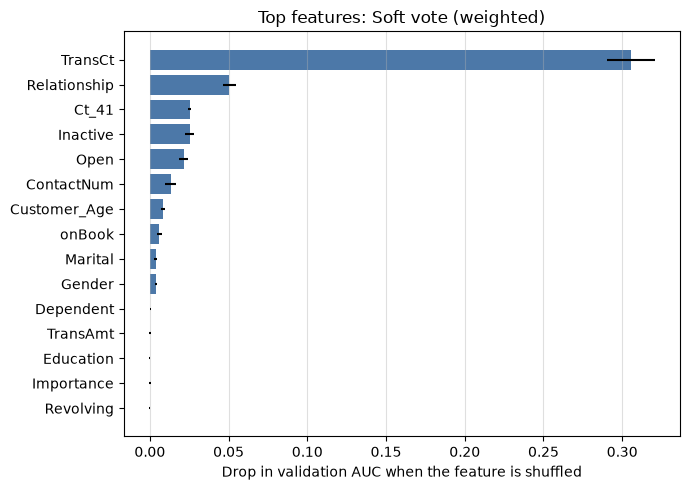

In [9]:
imp = permutation_importance(fitted[best_name], X_val, y_val, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
order = np.argsort(imp.importances_mean)[-15:]
plt.figure(figsize=(7, 5))
plt.barh(X.columns[order], imp.importances_mean[order], xerr=imp.importances_std[order], color="#4C78A8")
plt.xlabel("Drop in validation AUC when the feature is shuffled")
plt.title(f"Top features: {best_name}")
plt.grid(axis="x", alpha=0.4)
plt.tight_layout(); plt.show()

**Feature importance:** `TransCt` dominates: shuffling it lowers the validation AUC by about 0.3, far more than any other feature. The next most important are `Relationship`, `Ct_41`, `Inactive`, `Open` and `ContactNum` (each costing about 0.01 to 0.05 AUC), while `Dependent`, `TransAmt`, `Education`, `Importance` and `Revolving` have almost no effect on the model. 

### Final model and submission
The selected weighted soft-vote ensemble is refit on all 7,595 labeled rows (training and validation splits together), and then predicts the probability of class 2 for each of the 2,532 test rows. The probabilities (not hard class labels) are saved, one per line without a header, to `test_result_HW6Ensemble.csv`, since AUC depends on the ranking of the scores.

In [10]:
final_model = clone(models[best_name]).fit(X, y)

class2_index = list(final_model.classes_).index(2)
test_class2_prob = final_model.predict_proba(test)[:, class2_index]

assert len(test_class2_prob) == len(test), "row count mismatch"
print(f"Predictions: {len(test_class2_prob)} | min {test_class2_prob.min():.5f} | max {test_class2_prob.max():.5f}")

pd.DataFrame({"Class2_probability": test_class2_prob}).to_csv("test_result_HW6Ensemble.csv", index=False, header=False)

Predictions: 2532 | min 0.00003 | max 0.99794


## Summary
- **Data:** imbalanced (about 84% class 1, 16% class 2), no missing values, so AUC is used for all evaluation.
- **Models:** four tuned base models (random forest, extra trees, gradient boosting, logistic regression) and four ensembles (two soft votes, stacking and a weighted soft vote).
- **Best model:** the weighted soft vote of random forest and gradient boosting (CV AUC 0.951, validation AUC 0.945). It is only marginally better than gradient boosting alone, so most of the benefit comes from boosting.
- **Ensembles vs. single models:** ensembles of trees beat the linear baseline by about 0.06 AUC. Averaging models of similar quality (RF+ET) or including a weak model (logistic regression) gave little or no improvement, whereas combining the strongest model with a different type of model gave the best result.
- **Output:** `test_result_HW6Ensemble.csv` contains 2,532 predicted probabilities of class 2.

**Limitations:** differences among the top three models are within the CV noise, the ensemble weights were hand-picked using CV scores, and the hyperparameter search was a limited random search.